# From a mean size to a curve: the Rosin-Rammler distribution and the uniformity index

**Level 1: Fundamentals** · Needs: 02-classical-prediction/01-the-classical-equation-on-one-blast · Reading time: about 20 minutes

## Objectives

A mean size is one number. A crusher is specified against a percentile, usually the P80, so the classical model adds a distribution around the mean. This notebook builds that distribution for one blast and reads it.

By the end you will have:

- written the Rosin-Rammler curve and the Cunningham uniformity index that shapes it, and matched the engine on the Enusa blast `En1`;
- read the P20, P50 and P80 off the curve and compared the curve with the one the bake committed;
- seen how the uniformity index varies over the 91 blasts with a geometry, and what it does to the tail.

## Setup

Install the packages with the exact pins of `notebooks/requirements.txt`. The engine is `blastfrag`, published on PyPI; the other packages are its numerical base and the plotting library.

```bash
pip install blastfrag==0.4.0 numpy==2.5.3 matplotlib==3.11.2
```

This cell imports nothing from the notebook yet: it reads the installed versions from the package metadata and prints them, so the output records exactly which engine produced every number below.

In [1]:
# Print the installed version of every package this notebook uses
from importlib.metadata import version

for name in ("blastfrag", "numpy", "matplotlib",):
    print(f"{name}=={version(name)}")

blastfrag==0.4.0
numpy==2.5.3
matplotlib==3.11.2


## Data

| Source | Owner and URL | Licence class | File the notebook reads |
|---|---|---|---|
| The corpus and the reconstructed patterns | Hudaverdi, Kulatilake and Kuzu 2010, https://doi.org/10.1002/nag.957 | numeric facts reused with citation; the article never ships | the corpus inside the `blastfrag` wheel |
| The equations of the curve and of the uniformity index | Amoako, Jha and Zhong 2022, https://doi.org/10.3390/mining2020013 (Eqs. 5 and 7) | the equations are reproduced with citation | `bf.rosin_rammler`, `bf.cunningham_uniformity_index` |
| The committed distributions of the Enusa case | this repository (MIT), written by the offline bake | the product's own licence | `data/derived/real-enusa/case.json`, field `distributions` |

No dataset held for this work records a measured size distribution: only the mean `x50` is measured. The curves are model output, and this notebook says so where it reads them.

## Method

The Rosin-Rammler curve gives the fraction passing a mesh of size `x` (Amoako, Jha and Zhong 2022, https://doi.org/10.3390/mining2020013, Eq. 5):

```
P(x) = 1 - exp( -0.693 * (x / x50)^n )
```

The 0.693 is `ln 2`, which makes `x50` the size through which 50 percent passes. The exponent `n` is the uniformity index: a large `n` means a narrow, uniform size range; a small `n` means a wide spread with both oversize and fines. Cunningham's 1987 index (Eq. 7 of the same paper) computes `n` from the pattern:

```
n = (2.2 - 14 B/d) * sqrt((1 + S/B) / 2) * (1 - W/B) * (|BCL - CCL| / L + 0.1)^0.1 * (L / H)
```

with burden `B` in metres, hole diameter `d` in **millimetres**, spacing `S`, drilling deviation `W`, charge length `L`, bench height `H` and the bottom and column charge lengths `BCL` and `CCL`. The mixed units are a trap: `B/d` here is about 0.027 and not the dimensionless 27 the corpus tabulates. The engine takes a single continuous column, so the charge term is constant.

### Step 1: the mean size and the index for one blast

The cell takes `En1`, gets its pattern and the classical mean size from the previous topic, and computes the uniformity index with the engine and by hand, so the mixed units are visible.

In [2]:
# Imports, the blast, its classical mean size and its uniformity index (engine and by hand)
import json
import math
from pathlib import Path

import blastfrag as bf
import matplotlib.pyplot as plt
import numpy as np

DERIVED = Path("../../../data/derived")
train = bf.load_training_corpus()
blast = next(b for b in train if b.blast_id == "En1")
pattern = bf.reconstruct_pattern(blast)
x50 = bf.Kuznetsov().predict_one(blast).x50_m
n_engine = bf.cunningham_uniformity_index(pattern)

# By hand: burden in metres over the diameter in millimetres, single continuous column
b_over_d = pattern.burden_m / pattern.hole_diameter_mm
n_hand = ((2.2 - 14 * b_over_d) * math.sqrt((1 + pattern.spacing_m / pattern.burden_m) / 2)
          * (1 - pattern.drill_deviation_m / pattern.burden_m) * (0.1 ** 0.1) * (pattern.charge_length_m / pattern.bench_height_m))
print(f"x50 = {x50:.4f} m")
print(f"B/d (m per mm) = {b_over_d:.4f}  against the tabulated ratio {blast.B_over_D}")
print(f"n engine = {n_engine:.4f} | n by hand = {n_hand:.4f} | equal: {abs(n_engine - n_hand) < 1e-12}")

x50 = 0.4399 m
B/d (m per mm) = 0.0273  against the tabulated ratio 27.27
n engine = 0.6321 | n by hand = 0.6321 | equal: True


### Step 2: the curve, and what a crusher reads from it

`rosin_rammler` evaluates the curve on the engine's shared logarithmic sieve grid, from 0.1 mm to 3 m. The returned `SizeDistribution` can be asked for the size passing any fraction. The cell reads the P20, P50 and P80, and the characteristic size through which 63.2 percent passes.

In [3]:
# Build the curve and read its percentiles
curve = bf.rosin_rammler(x50, n_engine)
print("points on the sieve grid:", len(curve.sizes_m), "| from", f"{curve.sizes_m[0]:.4f}", "to", f"{curve.sizes_m[-1]:.2f}", "m")
for fraction in (0.2, 0.5, 0.8):
    print(f"P{int(fraction * 100)} = {curve.percentile_m(fraction):.4f} m")
print(f"characteristic size (63.2 % passes) = {curve.detail['characteristic_size_m']:.4f} m")
print(f"fraction passing the measured x50 of this blast ({blast.x50_m} m) = {curve.passing_at(blast.x50_m):.3f}")

points on the sieve grid: 241 | from 0.0001 to 3.00 m
P20 = 0.0732 m
P50 = 0.4399 m
P80 = 1.6679 m
characteristic size (63.2 % passes) = 0.7855 m
fraction passing the measured x50 of this blast (0.37 m) = 0.463


### Step 3: compare with the committed curve

The bake wrote the curve of this blast into `case.json`, rounded to six decimals. The cell compares it with the one just built, point by point.

In [4]:
# Largest point-by-point difference against the committed Kuz-Ram curve
artifact = json.loads((DERIVED / "real-enusa" / "case.json").read_text(encoding="utf-8"))
committed = artifact["distributions"]["kuz-ram"]
print("committed curve is for blast:", artifact["representative_blast_id"])
gap = max(abs(a - b) for a, b in zip(curve.passing, committed["passing"]))
print(f"largest difference in the passing fraction = {gap:.1e}  (committed values are rounded to 6 decimals)")
print("committed P80 =", round(committed["p80_m"], 4), "m | rebuilt =", round(curve.percentile_m(0.8), 4), "m")

committed curve is for blast: En1
largest difference in the passing fraction = 5.0e-07  (committed values are rounded to 6 decimals)
committed P80 = 1.6679 m | rebuilt = 1.6679 m


### Step 4: the uniformity index across the corpus

The index depends on the pattern only. The cell computes it for all 91 blasts with a geometry and draws the curve of three of them: the one with the smallest index, the median and the largest, at the same mean size so only the shape differs.

blasts: 91 | n min 0.184 | median 0.950 | max 1.362


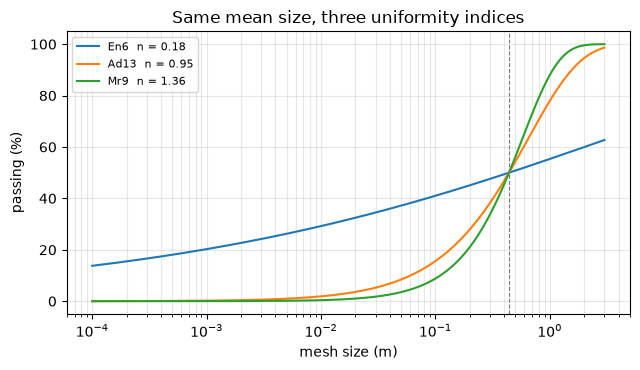

In [5]:
# The uniformity index of every blast with a geometry, and three curves at the same mean size
indices = {b.blast_id: bf.cunningham_uniformity_index(bf.reconstruct_pattern(b)) for b in train if bf.has_absolute_geometry(b)}
values = np.array(list(indices.values()))
print("blasts:", len(values), f"| n min {values.min():.3f} | median {np.median(values):.3f} | max {values.max():.3f}")
ordered = sorted(indices, key=indices.get)
picks = [ordered[0], ordered[len(ordered) // 2], ordered[-1]]
fig, ax = plt.subplots(figsize=(6.5, 3.8))
for pick in picks:
    shape = bf.rosin_rammler(x50, indices[pick])
    ax.plot(shape.sizes_m, [100 * p for p in shape.passing], label=f"{pick}  n = {indices[pick]:.2f}")
ax.axvline(x50, color="#777", lw=0.8, ls="--")
ax.set_xscale("log")
ax.set_xlabel("mesh size (m)")
ax.set_ylabel("passing (%)")
ax.set_title("Same mean size, three uniformity indices")
ax.legend(fontsize=8)
ax.grid(alpha=0.3, which="both")
fig.tight_layout()
plt.show()

## Results

**The curve is fixed by two numbers.** The mean size sets where the curve crosses 50 percent and the uniformity index sets how steeply it climbs. Rebuilt by hand and with the engine they agree, and the engine's curve matches the committed one to the rounding of the file.

**The tail is long.** For `En1` the uniformity index is below the 0.7 to 2 range that Amoako, Jha and Zhong state as usual, so the curve is wide: the P80 is several times the mean size, while the fraction passing the measured x50 (about 46 percent, in the output above) is close to the 50 percent of the predicted one. Across the corpus the index spans a factor of seven, so the shape differs a great deal from blast to blast even at one mean size.

**What this does not show.** The curve was never compared with a measured size distribution, because none is available: the corpus measures only `x50`. A P80 read from this curve is a model output whose shape nothing here validates. A P80 of this size, larger than the in situ blocks of the site, also signals that the curve needs the structural cap that the next notebook introduces.

## Summary

- A Rosin-Rammler curve needs the mean size and a uniformity index; the index comes from the pattern, with its mixed-unit trap.
- The engine, a by-hand calculation and the committed artifact agree on the curve.
- The corpus spans a wide range of indices, so the shape, and the P80, differ much more than the mean.
- Next: notebook 02 adds the Swebrec and crush-zone curves and the cap at the in situ block.

## References

- Amoako, Jha and Zhong 2022, https://doi.org/10.3390/mining2020013 (Eqs. 5 and 7)
- Hudaverdi, Kulatilake and Kuzu 2010, https://doi.org/10.1002/nag.957 (the corpus)
- `blastfrag` 0.4.0, the engine, on PyPI: https://pypi.org/project/blastfrag/